##### **CAR PRICE PREDICTION WITH LINEAR REGRESSION**

In [1]:
# Import necessary libraries
import os 
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    root_mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_seq_items", None)


c:\Users\pablo\Documents\Proyectos Data Science\Car Model Price Prediction\Ent1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Once we have the libraries we will load and explore the data

In [2]:
# Download the dataset from Kaggle if it is not already stored locally.
# This keeps the original data source and allows rerunning the notebook from the project folder.
local_file = os.path.join("Dataset", "CarPrice_Assignment.csv")
if os.path.isfile(local_file):
    path = "Dataset"
else:
    path = kagglehub.dataset_download("hellbuoy/car-price-prediction", output_dir="Dataset")

print("Carpeta de trabajo:", os.getcwd())
print("Path to dataset files:", path)
print("Archivos:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))
print("Shape: ", df.shape)

Carpeta de trabajo: c:\Users\pablo\Documents\Proyectos Data Science\Car Model Price Prediction
Path to dataset files: Dataset
Archivos: ['.complete', 'CarPrice_Assignment.csv', 'Data Dictionary - carprices.xlsx']
Shape:  (205, 26)


In [3]:
#Data exploration
print(df.head(5))
df.info()  # df.info() prints the summary itself; print(...) would add an unnecessary None

#Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

#Check for duplicates
print("Number of duplicate rows: ", df.duplicated().sum())


   car_ID  symboling                   CarName fueltype aspiration doornumber  \
0       1          3        alfa-romero giulia      gas        std        two   
1       2          3       alfa-romero stelvio      gas        std        two   
2       3          1  alfa-romero Quadrifoglio      gas        std        two   
3       4          2               audi 100 ls      gas        std       four   
4       5          2                audi 100ls      gas        std       four   

       carbody drivewheel enginelocation  wheelbase  carlength  carwidth  \
0  convertible        rwd          front       88.6      168.8      64.1   
1  convertible        rwd          front       88.6      168.8      64.1   
2    hatchback        rwd          front       94.5      171.2      65.5   
3        sedan        fwd          front       99.8      176.6      66.2   
4        sedan        4wd          front       99.4      176.6      66.4   

   carheight  curbweight enginetype cylindernumber  engi

In [4]:
#Data cleaning 
# Now we will clean the data and ensure that the text columns are correct
text_cols = df.select_dtypes(include=['object', 'string']).columns  # Compatible with Pandas string dtype

for col in text_cols:
    print(f"Unique values in column '{col}':")
    print(df[col].value_counts().to_dict())

# 1. Taking the car brand from the car name column
print("CarName unique values: ", df['CarName'].unique())
df['Car_Brand'] = df['CarName'].str.split(' ').str[0].str.lower()

#2. Replacing text columns to number columns
word_to_num = { 'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'twelve': 12}

df['doornumber'] = df['doornumber'].map(word_to_num)
df['cylindernumber'] = df['cylindernumber'].map(word_to_num)
# Check that every original category was successfully mapped to a number.
assert df[['doornumber', 'cylindernumber']].notna().all().all(), "Unmapped door/cylinder label found"

#We could also use the following code to replace the text columns to number columns
# Note: astype(int) would only work AFTER converting word labels to numbers (as done above).

#3. Check the car brand column for any typos or inconsistencies
print("Car_Brand: ", df['Car_Brand'].unique())
car_brand_corrections = {
    'alfa-romero': 'alfa-romeo',
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen'
}

df['Car_Brand'] = df['Car_Brand'].replace(car_brand_corrections)

#4. Drop columns that we don't need for the analysis
df = df.drop(columns= ['car_ID', 'CarName'])



Unique values in column 'CarName':
{'peugeot 504': 6, 'toyota corona': 6, 'toyota corolla': 6, 'subaru dl': 4, 'honda civic': 3, 'mazda 626': 3, 'mitsubishi outlander': 3, 'mitsubishi g4': 3, 'mitsubishi mirage g4': 3, 'toyota mark ii': 3, 'audi 100ls': 2, 'bmw 320i': 2, 'bmw x3': 2, 'honda civic cvcc': 2, 'honda accord': 2, 'isuzu D-Max ': 2, 'mazda rx-4': 2, 'mazda glc deluxe': 2, 'mazda glc': 2, 'mazda rx-7 gs': 2, 'nissan rogue': 2, 'nissan latio': 2, 'nissan clipper': 2, 'peugeot 604sl': 2, 'plymouth fury iii': 2, 'porsche cayenne': 2, 'saab 99e': 2, 'saab 99le': 2, 'saab 99gle': 2, 'subaru': 2, 'toyota corolla 1200': 2, 'toyota corolla liftback': 2, 'toyota starlet': 2, 'volkswagen dasher': 2, 'volvo 145e (sw)': 2, 'volvo 144ea': 2, 'volvo 244dl': 2, 'volvo 264gl': 2, 'alfa-romero giulia': 1, 'alfa-romero stelvio': 1, 'alfa-romero Quadrifoglio': 1, 'audi 100 ls': 1, 'audi fox': 1, 'audi 5000': 1, 'audi 4000': 1, 'audi 5000s (diesel)': 1, 'bmw x1': 1, 'bmw z4': 1, 'bmw x4': 1, 'bm

Once we have all our data ready we have to determine the best variables to determine the price

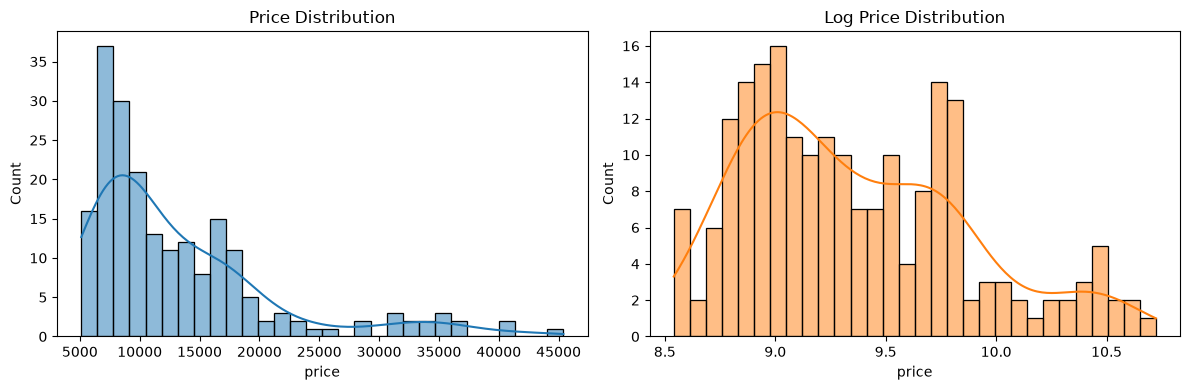

Correlation with price:
 enginesize          0.874145
curbweight          0.835305
horsepower          0.808139
carwidth            0.759325
cylindernumber      0.718305
carlength           0.682920
wheelbase           0.577816
boreratio           0.553173
carheight           0.119336
stroke              0.079443
compressionratio    0.067984
doornumber          0.031835
symboling          -0.079978
peakrpm            -0.085267
citympg            -0.685751
highwaympg         -0.697599
dtype: float64


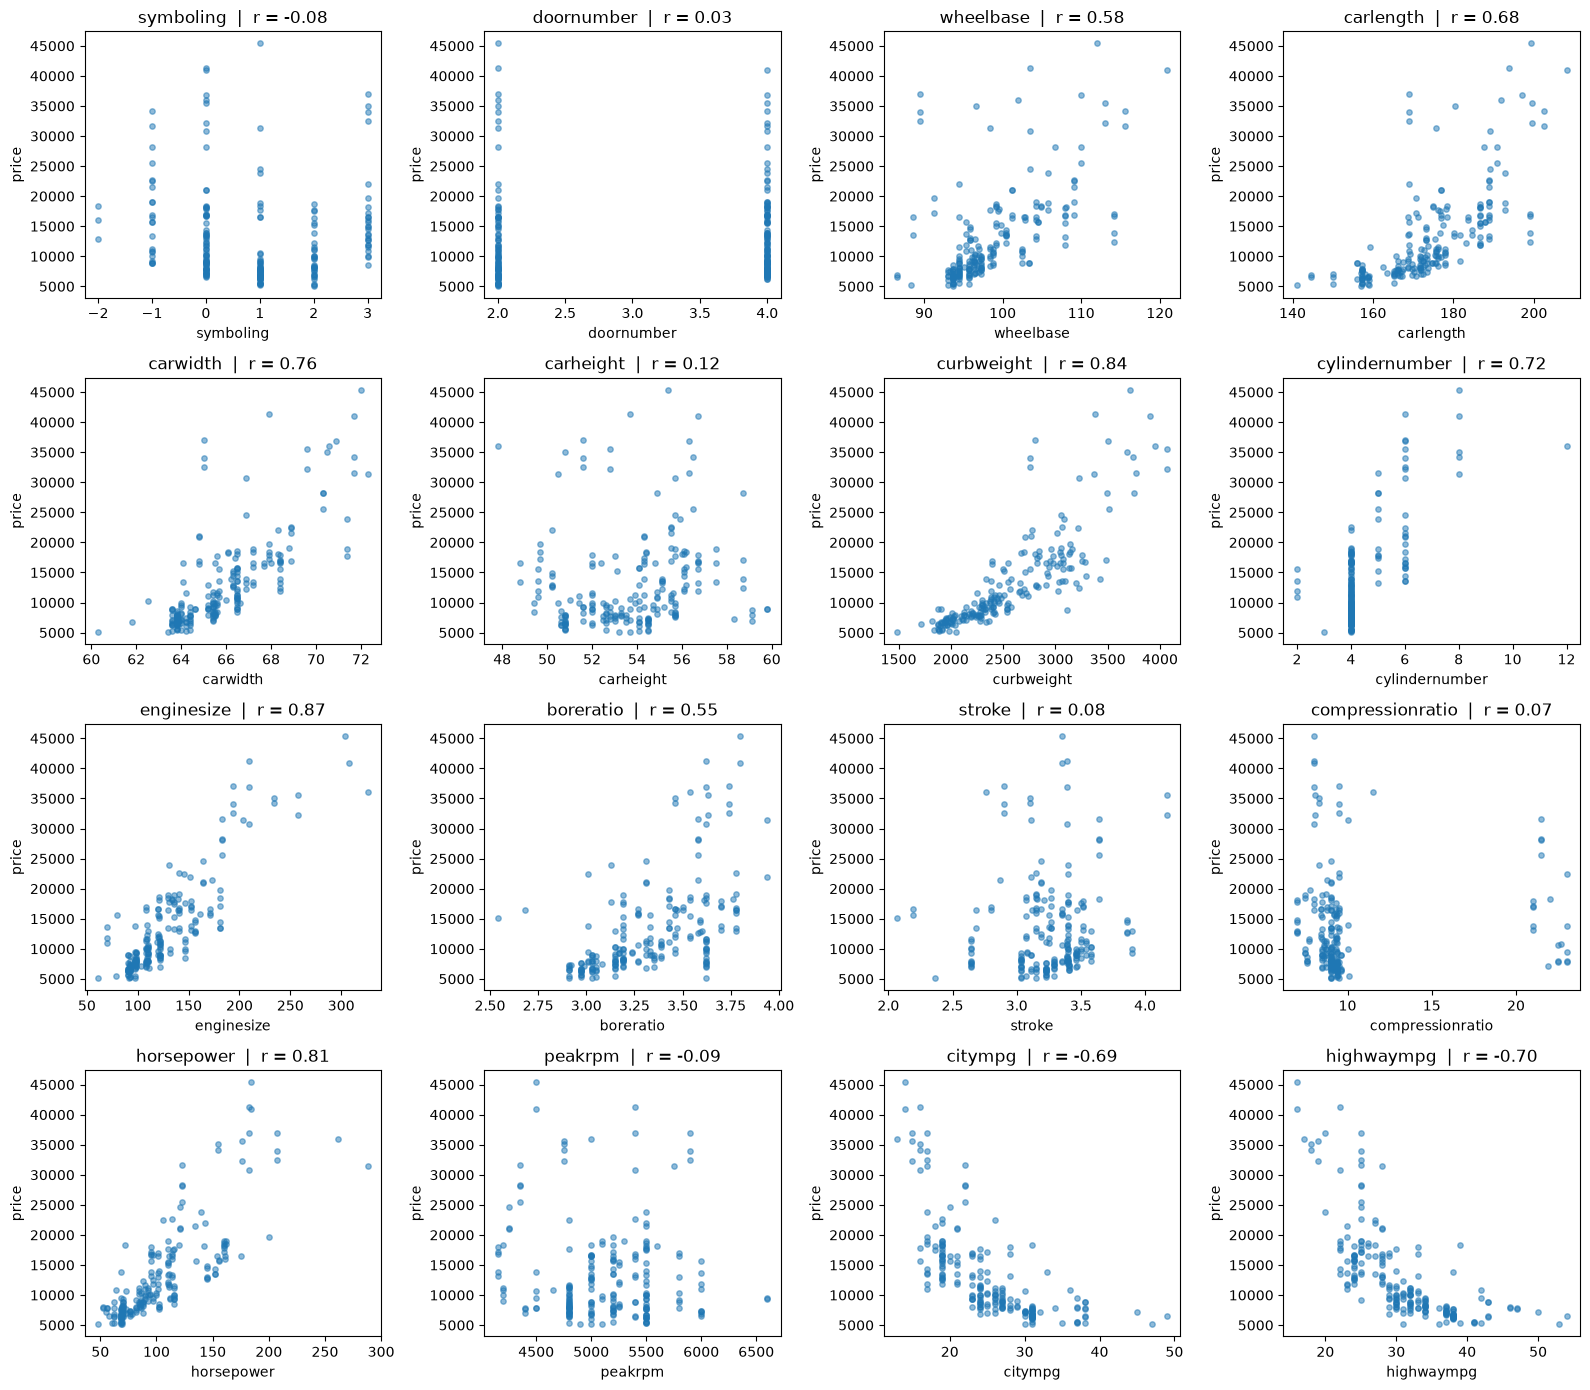

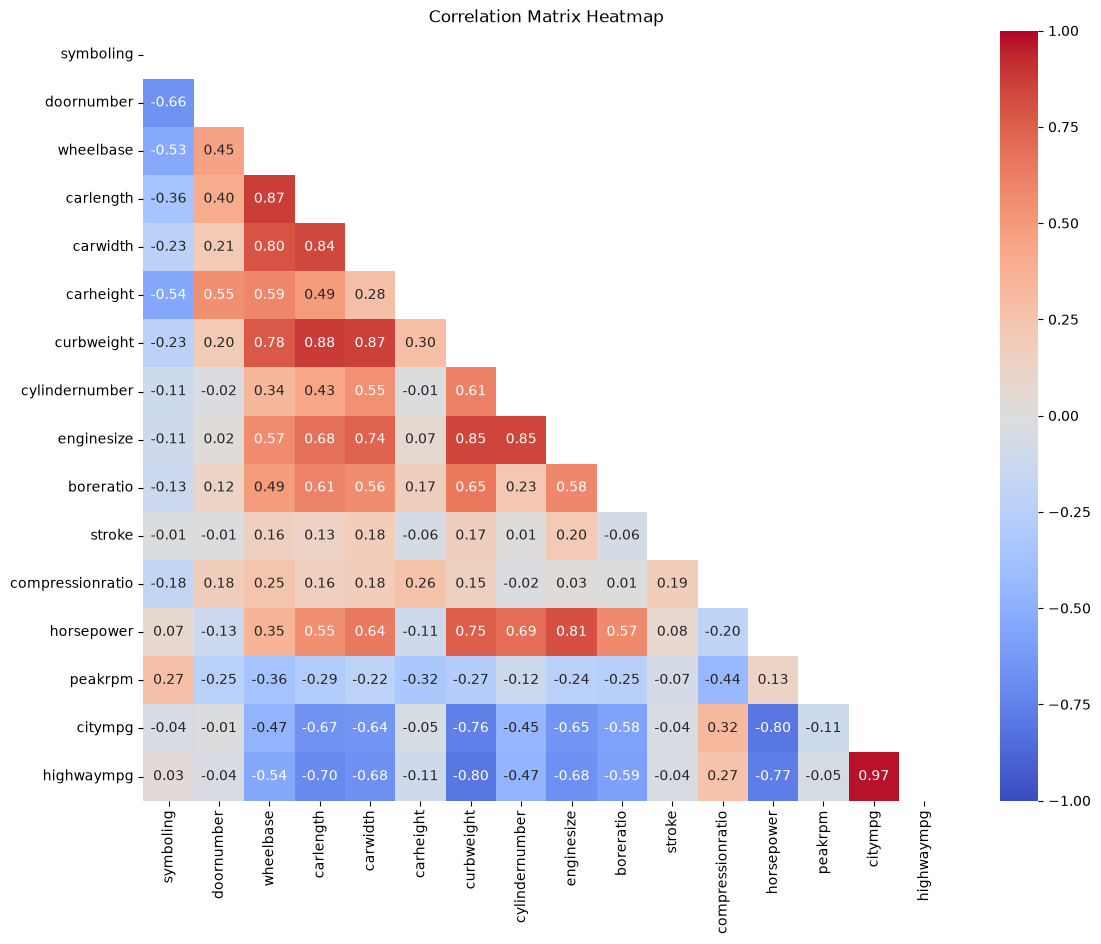

In [5]:
#1. We are going to find the price distribution 
# First we will check the simetry of the price distribution 
fig, ax = plt.subplots(1,2, figsize=(12, 4))
sns.histplot(df['price'], bins=30, kde=True, color='tab:blue', ax=ax[0] )
ax[0].set_title('Price Distribution')
sns.histplot(np.log(df['price']), bins=30, kde=True, color='tab:orange', ax=ax[1])
ax[1].set_title('Log Price Distribution')
plt.tight_layout()
plt.show()

# The distribution is right-skewed. We inspect log(price) here, but the regression below still predicts price on its original scale.

#2.We are going to find the correlation between the features and the target variable (price)
# We choose the numeric variables to find correlation with price

num_cols = df.select_dtypes(include='number').columns.drop('price')

corr_price = df[num_cols].corrwith(df['price']).sort_values(ascending=False)
print("Correlation with price:\n", corr_price)

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, col in zip(axes.flat, num_cols):
    ax.scatter(df[col], df["price"], alpha=0.5, s=15)
    ax.set_xlabel(col)
    ax.set_ylabel("price")
    ax.set_title(f"{col}  |  r = {corr_price[col]:.2f}")
for ax in axes.flat[len(num_cols):]:  # Hide unused subplot(s).
    ax.set_visible(False)
plt.tight_layout()
plt.show()

# We are going to find colinearity between the features, we will use a heatmap to visualize the correlation matrix
corr_matrix = df[num_cols].corr()
#display(corr_matrix.round(2))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(13, 10)) 
sns.heatmap(corr_matrix,mask = mask, annot=True, fmt=".2f", center = 0, cmap = 'coolwarm', vmax=1, vmin=-1)
plt.title("Correlation Matrix Heatmap")
plt.show()

Categorical variables:  7 Index(['fueltype', 'aspiration', 'carbody', 'drivewheel', 'enginelocation',
       'enginetype', 'fuelsystem'],
      dtype='str')


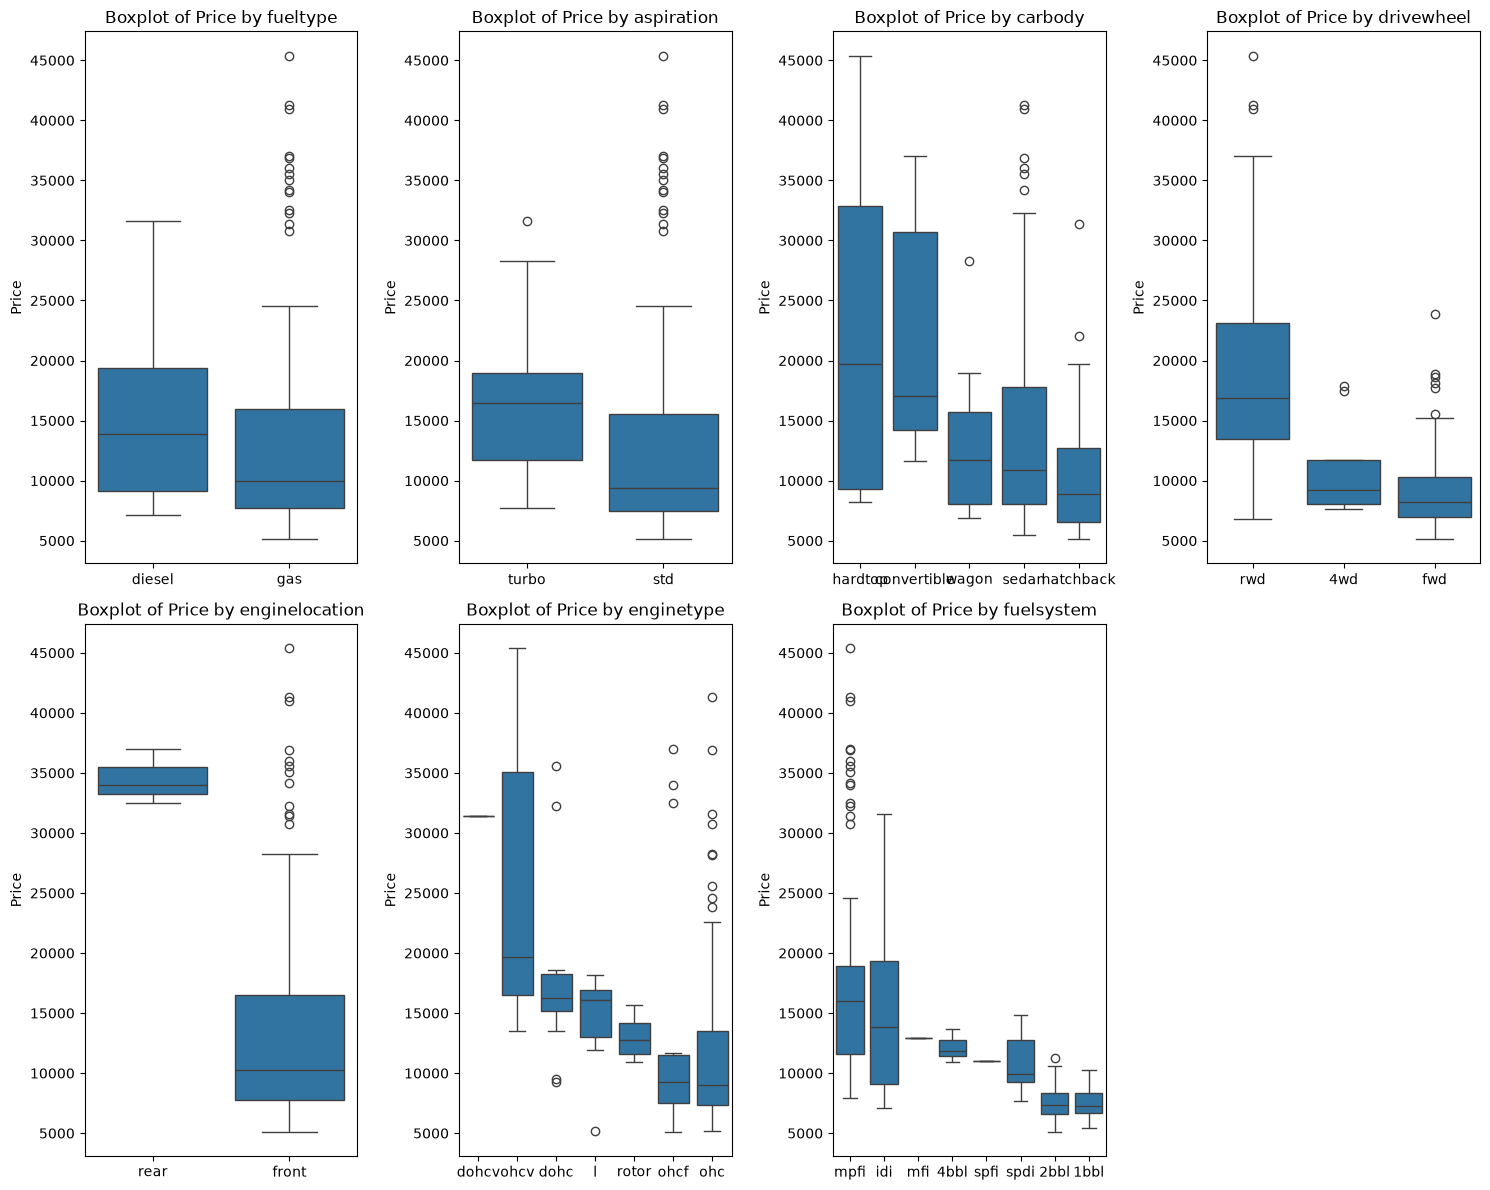

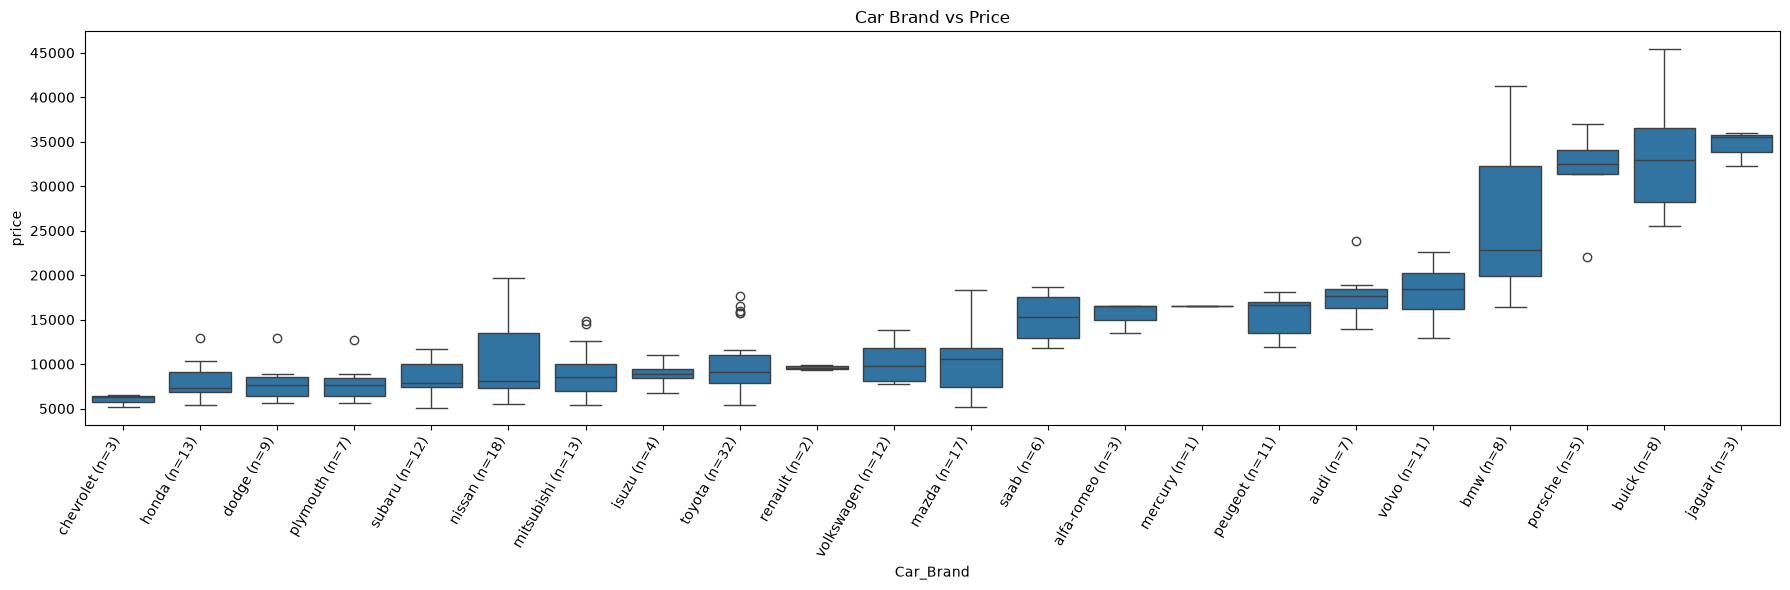

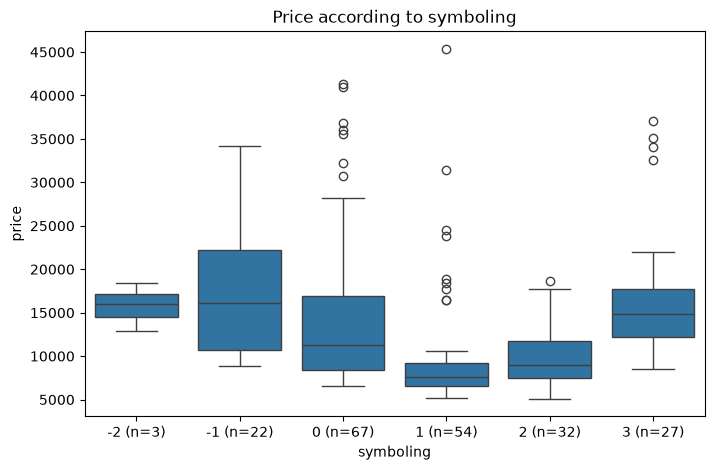

In [6]:
# We are going to study now the categorical variables and their relationship with the target variable (price)
# As they are categorical, they cannot be studied with correlation, 
# so we will use boxplots to visualize the relationship between the categorical variables and the target variable (price)

cat_var = df.select_dtypes(include=['object', 'string']).columns.drop("Car_Brand")
print("Categorical variables: ", len(cat_var), cat_var)


fig, axes = plt.subplots(2, 4, figsize=(15, 12))

for ax, col in zip(axes.flat, cat_var):
    order = df.groupby(col)['price'].median().sort_values(ascending=False).index
    sns.boxplot(x=col, y='price', data=df, order = order, ax=ax)
    ax.set_title(f"Boxplot of Price by {col}")
    ax.set_xlabel('')
    ax.set_ylabel('Price')
for ax in axes.flat[len(cat_var):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

order = df.groupby("Car_Brand")["price"].median().sort_values().index
counts = df["Car_Brand"].value_counts()

#2. Different way to visualize Car brand and price because all of the car brands that
#we have
plt.figure(figsize=(18, 6))
ax = sns.boxplot(data=df, x="Car_Brand", y="price", order=order)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{b} (n={counts[b]})" for b in order], rotation=60, ha="right")
ax.set_title("Car Brand vs Price")
plt.tight_layout()
plt.show()

#3.Special graph also for symboling variable
order = sorted(df["symboling"].unique())
counts = df["symboling"].value_counts()

plt.figure(figsize=(8, 5))
ax = sns.boxplot(data=df, x="symboling", y="price", order=order)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{s} (n={counts[s]})" for s in order])
ax.set_title("Price according to symboling")
plt.show()
    


We have already explore our modle variables and relations, so we are ready to start building our regression model, the next steps are:
1. Simplify text variables before converting them to numbers
2. Divide the train and test data
3. Convert text variables to dummy
4. Scale numeric variables
 

In [7]:
cat_var = df.select_dtypes(exclude='number').columns.drop("Car_Brand")

print("Exploring duplicate variables")
for col in cat_var:
    print(f"\n{col}:")
    print(df[col].value_counts().to_dict())

# All cars with fuelsystem == idi are diesel; this is overlap, not complete duplication.
print("Fuel type vs. fuel system:")
display(pd.crosstab(df["fueltype"], df["fuelsystem"]))

print("Engine type vs. cylinder number:")
display(pd.crosstab(df["enginetype"], df["cylindernumber"]))

# 3. Explore differences in compression ratio between fuel types.
print("Compression ratio by fuel type:")
display(df.groupby("fueltype")["compressionratio"].describe().round(1))

Exploring duplicate variables

fueltype:
{'gas': 185, 'diesel': 20}

aspiration:
{'std': 168, 'turbo': 37}

carbody:
{'sedan': 96, 'hatchback': 70, 'wagon': 25, 'hardtop': 8, 'convertible': 6}

drivewheel:
{'fwd': 120, 'rwd': 76, '4wd': 9}

enginelocation:
{'front': 202, 'rear': 3}

enginetype:
{'ohc': 148, 'ohcf': 15, 'ohcv': 13, 'dohc': 12, 'l': 12, 'rotor': 4, 'dohcv': 1}

fuelsystem:
{'mpfi': 94, '2bbl': 66, 'idi': 20, '1bbl': 11, 'spdi': 9, '4bbl': 3, 'mfi': 1, 'spfi': 1}
Fuel type vs. fuel system:


fuelsystem,1bbl,2bbl,4bbl,idi,mfi,mpfi,spdi,spfi
fueltype,,,,,,,,
diesel,0,0,0,20,0,0,0,0
gas,11,66,3,0,1,94,9,1


Engine type vs. cylinder number:


cylindernumber,2,3,4,5,6,8,12
enginetype,,,,,,,
dohc,0,0,6,0,6,0,0
dohcv,0,0,0,0,0,1,0
l,0,1,11,0,0,0,0
ohc,0,0,130,11,7,0,0
ohcf,0,0,12,0,3,0,0
ohcv,0,0,0,0,8,4,1
rotor,4,0,0,0,0,0,0


Compression ratio by fuel type:


,count,mean,std,min,25%,50%,75%,max
fueltype,,,,,,,,
diesel,20.0,22.0,0.8,21.0,21.4,22.0,22.8,23.0
gas,185.0,8.9,0.7,7.0,8.5,9.0,9.4,11.5


In [8]:
cat_cols = df.select_dtypes(exclude="number").columns.drop("Car_Brand")

for col in cat_cols:
    counts = df[col].value_counts()
    rare = counts[counts < 5]
    if len(rare) > 0:
        print(f"{col}: {rare.to_dict()}")

print("symboling:", df["symboling"].value_counts().sort_index().to_dict())



df_model = df.copy()
# Modeling choices: fuel system overlaps with fuel type; rear-engine cars are very rare.
# Dropping fuelsystem may remove additional information; revisit this choice in model improvements.
df_model = df_model.drop(columns=["fuelsystem", "enginelocation"])

#Group rares into other
df_model['enginetype'] = df_model['enginetype'].replace({'rotor': 'other', 'dohcv': 'other'})

# symboling as category, merging -2 (3 cars) into -1
df_model["symboling"] = df_model["symboling"].replace({-2: -1}).astype(str)

# Checks
print("enginetype:", df_model["enginetype"].value_counts().to_dict())
print("symboling:", df_model["symboling"].value_counts().to_dict())
print("Shape:", df_model.shape)

enginelocation: {'rear': 3}
enginetype: {'rotor': 4, 'dohcv': 1}
fuelsystem: {'4bbl': 3, 'mfi': 1, 'spfi': 1}
symboling: {-2: 3, -1: 22, 0: 67, 1: 54, 2: 32, 3: 27}
enginetype: {'ohc': 148, 'ohcf': 15, 'ohcv': 13, 'dohc': 12, 'l': 12, 'other': 5}
symboling: {'0': 67, '1': 54, '2': 32, '3': 27, '-1': 25}
Shape: (205, 23)


We have all of our data clean and variables ready to work, we are now going to split the dataset for train and test

In [9]:
df_train, df_test = train_test_split(df_model, test_size=0.3, random_state=100)


print("Train:", df_train.shape)
print("Test:", df_test.shape)


#We have to check that all variables are included in both dataset to check that we can learn
#from them and that we can also test them

for col in df_train.select_dtypes(exclude="number").columns:
    missing = set(df_test[col].dropna()) - set(df_train[col].dropna())
    if missing:
        print(f"{col}: categories not in train -> {missing}")



Train: (143, 23)
Test: (62, 23)
Car_Brand: categories not in train -> {'mercury'}


We have a problem with car brand, although it has 22 different values and we dont have enough data to work with 22 brands so we will split it into brand_tier (low, mid, high)

In [10]:
def price_tier(price):
    if price < 10000:
        return "Low"
    elif price < 20000:
        return "Medium"
    else:
        return "High"

# Compute brand medians on TRAIN ONLY: using the full dataset would leak target values from test.
brand_median = df_train.groupby('Car_Brand')['price'].median().sort_values()

brand_tier = brand_median.apply(price_tier)

print("Brand tiers:", brand_median.round(0))

df_train['Brand_Tier'] = df_train['Car_Brand'].map(brand_tier)
df_test['Brand_Tier'] = df_test['Car_Brand'].map(brand_tier).fillna('Medium')  # Fallback for unseen brands

df_train = df_train.drop(columns=['Car_Brand'])
df_test = df_test.drop(columns=['Car_Brand'])

print("Train shape:", df_train.shape)
print("\nTrain:", df_train['Brand_Tier'].value_counts().to_dict())
print("Test shape:", df_test.shape)
print("\nTest:", df_test['Brand_Tier'].value_counts().to_dict())

Brand tiers: Car_Brand
chevrolet      6295.0
dodge          6534.0
plymouth       7150.0
honda          7295.0
nissan         7899.0
subaru         8013.0
mitsubishi     8189.0
isuzu          8916.0
toyota         9398.0
renault        9595.0
mazda         10595.0
volkswagen    11595.0
saab          15510.0
alfa-romeo    16500.0
peugeot       16798.0
audi          17710.0
volvo         20218.0
bmw           22835.0
porsche       31400.0
buick         31600.0
jaguar        35550.0
Name: price, dtype: float64
Train shape: (143, 23)

Train: {'Low': 81, 'Medium': 39, 'High': 23}
Test shape: (62, 23)

Test: {'Low': 32, 'Medium': 18, 'High': 12}


In [11]:
#We have all of our data ready for the next step, which is to create a model to predict the price of a car based on its features. We will use a regression model for this task, as the target variable (price) is continuous.

cat_cols = df_train.select_dtypes(exclude="number").columns
print("Categorical columns:", list(cat_cols))

reference = {col: df_train[col].mode().iloc[0] for col in cat_cols}
print("Reference categories:", reference)

# Create dummies using TRAIN categories only: never learn column categories from the test set.
train_dummies = pd.get_dummies(df_train, columns=cat_cols, dtype=int)
test_dummies = pd.get_dummies(df_test, columns=cat_cols, dtype=int)

# Keep the reference-category strategy chosen above.
ref_cols = [f"{col}_{cat}" for col, cat in reference.items()]
train_dummies = train_dummies.drop(columns=ref_cols, errors="ignore")
test_dummies = test_dummies.drop(columns=ref_cols, errors="ignore")

# Align test columns to the schema learned from train; unseen categories become all-zero dummies.
test_dummies = test_dummies.reindex(columns=train_dummies.columns, fill_value=0)
assert train_dummies.columns.equals(test_dummies.columns)

train_dummies.head()

Categorical columns: ['symboling', 'fueltype', 'aspiration', 'carbody', 'drivewheel', 'enginetype', 'Brand_Tier']
Reference categories: {'symboling': '0', 'fueltype': 'gas', 'aspiration': 'std', 'carbody': 'sedan', 'drivewheel': 'fwd', 'enginetype': 'ohc', 'Brand_Tier': 'Low'}


,doornumber,wheelbase,carlength,carwidth,carheight,curbweight,cylindernumber,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,symboling_-1,symboling_1,symboling_2,symboling_3,fueltype_diesel,aspiration_turbo,carbody_convertible,carbody_hardtop,carbody_hatchback,carbody_wagon,drivewheel_4wd,drivewheel_rwd,enginetype_dohc,enginetype_l,enginetype_ohcf,enginetype_ohcv,enginetype_other,Brand_Tier_High,Brand_Tier_Medium
122,4,93.7,167.3,63.8,50.8,2191,4,98,2.97,3.23,9.4,68,5500,31,38,7609.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
125,2,94.5,168.9,68.3,50.2,2778,4,151,3.94,3.11,9.5,143,5500,19,27,22018.0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0
166,2,94.5,168.7,64.0,52.6,2300,4,98,3.24,3.08,9.4,112,6600,26,29,9538.0,0,1,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0
1,2,88.6,168.8,64.1,48.8,2548,4,130,3.47,2.68,9.0,111,5000,21,27,16500.0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1
199,4,104.3,188.8,67.2,57.5,3157,4,130,3.62,3.15,7.5,162,5100,17,22,18950.0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,1,0


We are going to scale the variables to have them all grouped between 0-1

15 columns to scale: ['doornumber', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'cylindernumber', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']


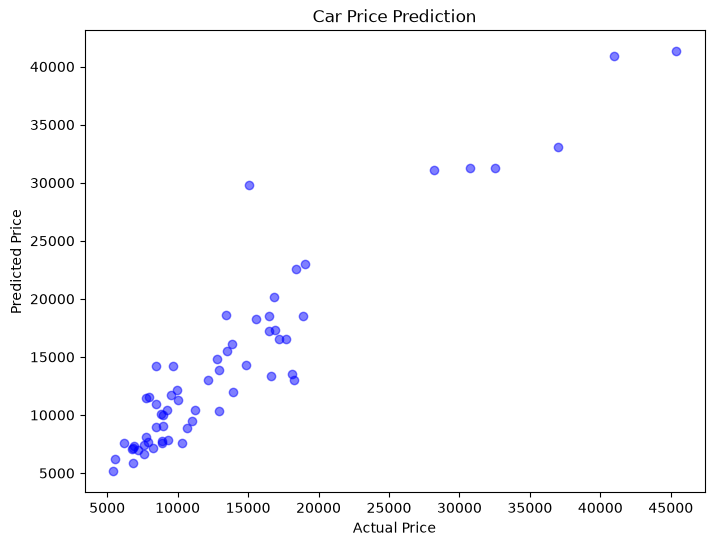

R² train: 0.942
R² test:  0.871
MSE test:  9019142
RMSE test: 3003
MAE test:  2044
MAPE test: 16.4 %


In [12]:
scaler = MinMaxScaler()

num_cols = df_train.select_dtypes(include="number").columns.drop("price")
print(len(num_cols), "columns to scale:", list(num_cols))

X_train = train_dummies.drop(columns="price").copy()
X_test = test_dummies.drop(columns="price").copy()
y_train = train_dummies["price"]
y_test = test_dummies["price"]

#Scale the numeric columns
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])


lm = LinearRegression()
lm.fit(X_train, y_train)

pred_test = lm.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred_test, color = "blue", alpha=0.5)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Car Price Prediction")
plt.show()  

print("R² train:", round(lm.score(X_train, y_train), 3))
print("R² test: ", round(lm.score(X_test, y_test), 3))
print("MSE test: ", round(mean_squared_error(y_test, pred_test)))
print("RMSE test:", round(root_mean_squared_error(y_test, pred_test)))

print("MAE test: ", round(mean_absolute_error(y_test, pred_test)))
print("MAPE test:", round(mean_absolute_percentage_error(y_test, pred_test) * 100, 1), "%")

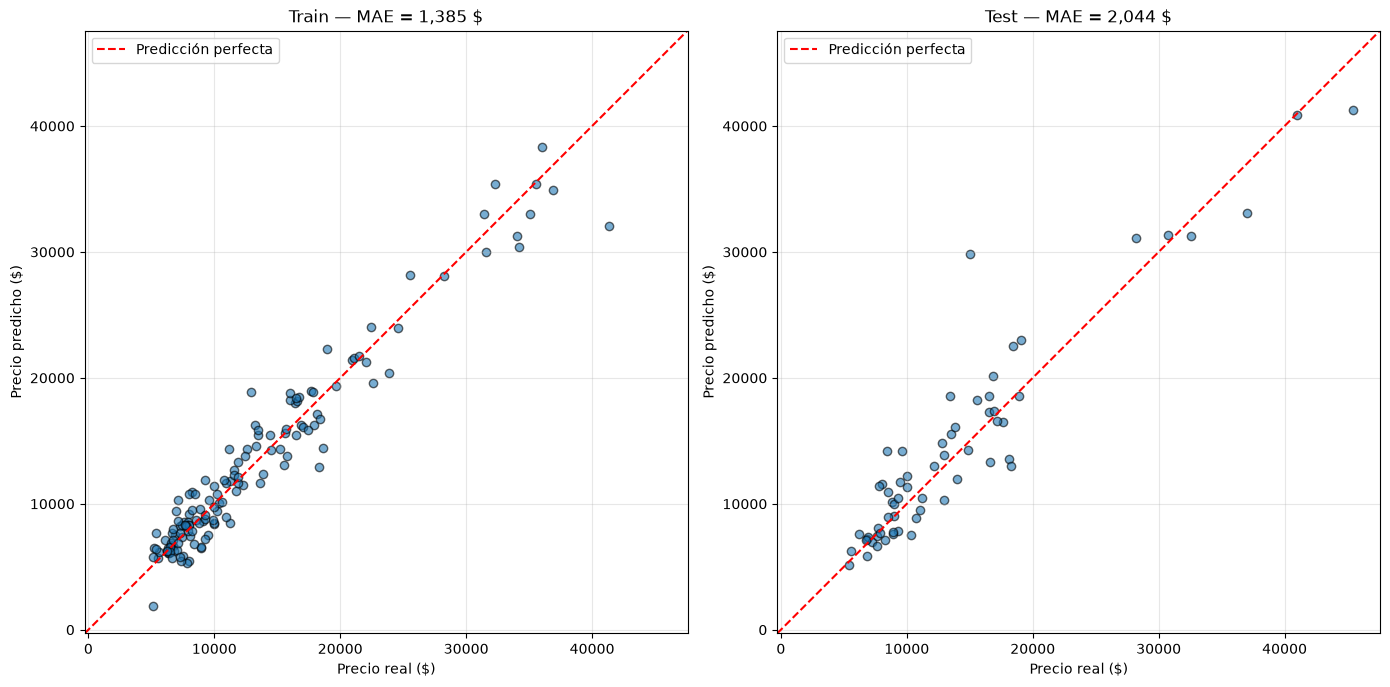

In [13]:
# Modelo de referencia con las 34 variables
lm_ref = LinearRegression().fit(X_train, y_train)
pred_train = lm_ref.predict(X_train)
pred_test = lm_ref.predict(X_test)

# Mismos límites en los dos gráficos para poder compararlos
all_values = np.concatenate([y_train, y_test, pred_train, pred_test])
margin = 0.05 * (all_values.max() - all_values.min())
lims = [all_values.min() - margin, all_values.max() + margin]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, y_real, y_pred, title in zip(axes,
                                     [y_train, y_test],
                                     [pred_train, pred_test],
                                     ["Train", "Test"]):
    ax.scatter(y_real, y_pred, alpha=0.6, edgecolor="k")

    # Diagonal: predicción perfecta (predicho = real)
    ax.plot(lims, lims, color="red", linestyle="--", label="Predicción perfecta")

    mae = mean_absolute_error(y_real, y_pred)
    ax.set_title(f"{title} — MAE = {mae:,.0f} $")
    ax.set_xlabel("Precio real ($)")
    ax.set_ylabel("Precio predicho ($)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Additional model diagnostics (added for portfolio readiness)

The previous two charts compare actual and predicted values. The next checks complement the original analysis by looking at **residuals** and comparing the model with a simple **training-mean baseline**. 

Baseline MAE (mean train price): $5,715
Linear regression MAE:         $2,044


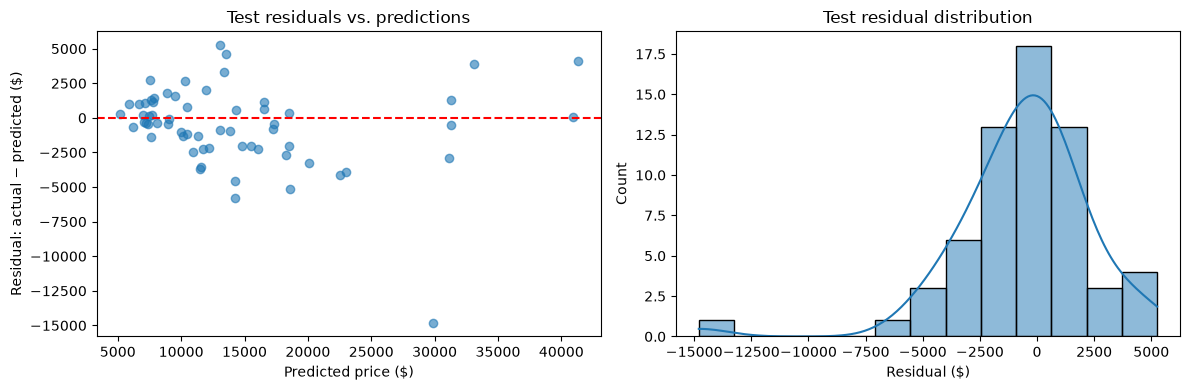

In [14]:
# Additional check: the residual is the difference between observed and predicted price.
residuals_test = y_test - pred_test
baseline_pred = np.full(len(y_test), y_train.mean())

print(f"Baseline MAE (mean train price): ${mean_absolute_error(y_test, baseline_pred):,.0f}")
print(f"Linear regression MAE:         ${mean_absolute_error(y_test, pred_test):,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pred_test, residuals_test, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted price ($)")
axes[0].set_ylabel("Residual: actual − predicted ($)")
axes[0].set_title("Test residuals vs. predictions")

sns.histplot(residuals_test, kde=True, color="tab:blue", ax=axes[1])
axes[1].set_title("Test residual distribution")
axes[1].set_xlabel("Residual ($)")
plt.tight_layout()
plt.show()

### Conclusions and limitations

**What this project demonstrates:** loading a public car-price dataset, inspecting data quality, normalizing labels, analyzing numerical and categorical predictors, selecting and simplifying variables, encoding features, scaling numerical inputs, training linear regression, and evaluating train/test performance.

**What to check after a clean run on the original CSV:**
- Record the newly calculated test R², MAE, RMSE, and MAPE (not the historical values from the pre-fix notebook).
- Compare train and test results for signs of overfitting, and inspect the residual plots for systematic patterns.
- Assess whether dropping `fuelsystem`, merging uncommon engine types, and manually selecting brand tiers improve or worsen generalization.
- Interpret results cautiously: only 205 observations, some rare categories, and a single split. Consider cross-validation in a future iteration.

**Note on target leakage:** the brand tier uses prices **from training only**. The test-set brand labels are mapped using those predefined tiers, with `Medium` as the declared fallback for unseen brands.